<a href="https://colab.research.google.com/github/Nosimon-Nahar/LabReport-3_CSE-418/blob/main/LaplacianMask.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

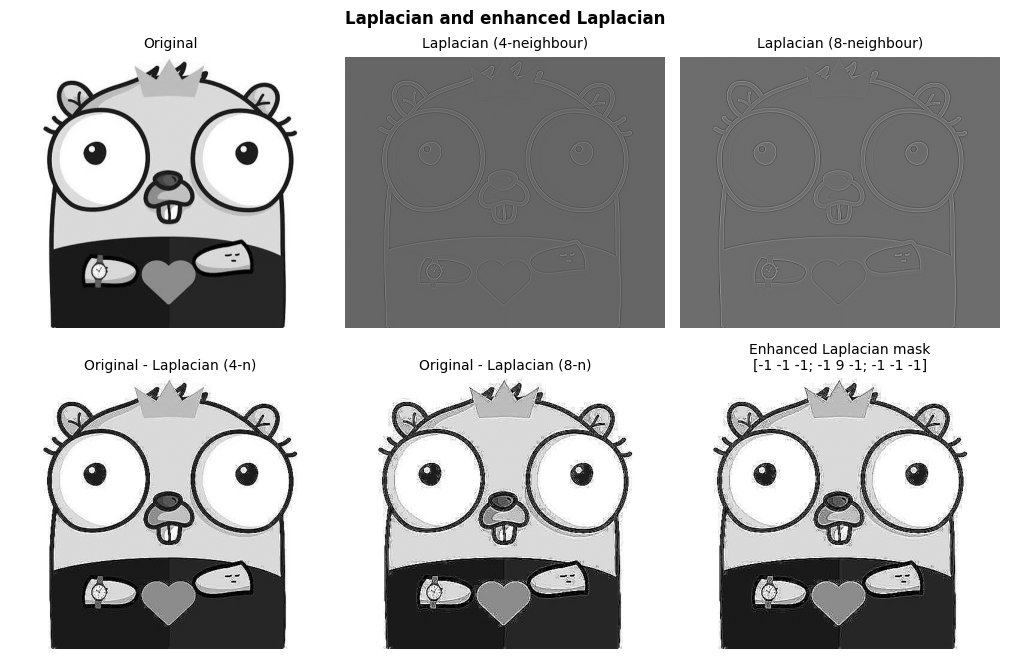

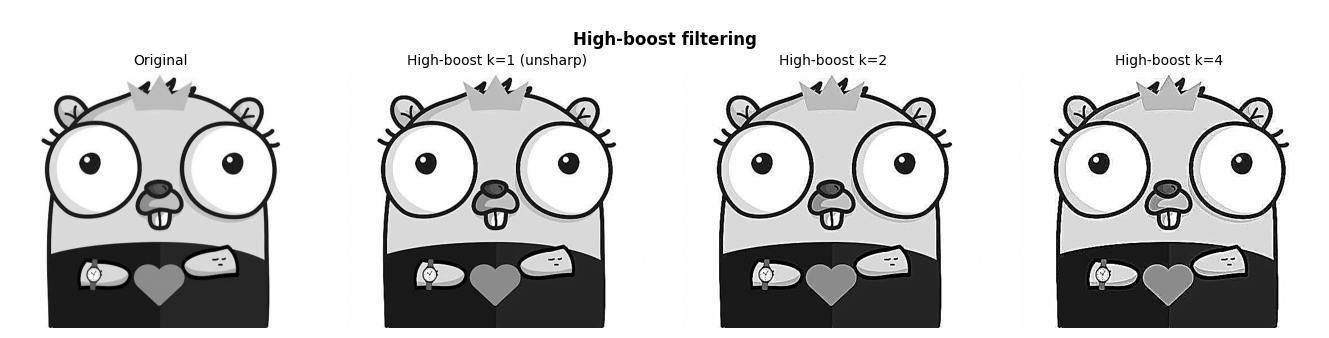

In [1]:
# Laplacian mask, enhanced Laplacian mask and high-boost mask
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_gray(path=None):
  # Load grayscale image; fall back to a synthetic test image.
    if path:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"Could not read image: {path}")
        return img
    x, y = np.meshgrid(np.linspace(0, 1, 512), np.linspace(0, 1, 512))
    img = 80 + 60 * x + 30 * np.sin(12 * y) * np.cos(8 * x)
    cv2.circle(img, (256, 256), 100, 170, -1)
    cv2.rectangle(img, (60, 60), (160, 160), 220, -1)
    img = cv2.GaussianBlur(img, (0, 0), 1.5)  # slightly soft so sharpening is visible
    return np.clip(img, 0, 255).astype(np.uint8)

def clip_u8(a):
    return np.clip(a, 0, 255).astype(np.uint8)

def normalize_u8(a):
  # Scale signed Laplacian output to 0..255 for display.
    a = a.astype(np.float64)
    rng = a.max() - a.min()
    return np.zeros(a.shape, np.uint8) if rng < 1e-12 else ((a - a.min()) / rng * 255).astype(np.uint8)

def convolve(img, kernel):
    return cv2.filter2D(img.astype(np.float32), cv2.CV_32F,
                        np.asarray(kernel, np.float32), borderType=cv2.BORDER_REPLICATE)

def gaussian_kernel(size=7, sigma=1.5):
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    k = np.exp(-(xx ** 2 + yy ** 2) / (2.0 * sigma ** 2))
    return k / k.sum()

# ---------------- Masks ----------------
LAPLACIAN_4 = np.array([[0, 1, 0],
                        [1, -4, 1],
                        [0, 1, 0]], np.float32) # 4-neighbour, negative centre
LAPLACIAN_8 = np.array([[1, 1, 1],
                        [1, -8, 1],
                        [1, 1, 1]], np.float32) # 8-neighbour (includes diagonals)
ENHANCED_LAPLACIAN = np.array([[-1, -1, -1],
                               [-1, 9, -1],
                               [-1, -1, -1]], np.float32) # image - Laplacian(8) in one mask

def high_boost(img, k=2.0, size=7, sigma=1.5):
    """ High-boost filtering:
        unsharp mask = f - blur(f)
        g = f + k * mask (k=1 -> unsharp masking, k>1 -> high-boost)
    """
    f = img.astype(np.float32)
    mask = f - convolve(img, gaussian_kernel(size, sigma))
    return clip_u8(f + k * mask)

def show(images, titles, cols, title, fname):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 3.4 * rows))
    for ax, im, t in zip(np.atleast_1d(axes).ravel(), images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    fig.savefig(fname, dpi=120)

def main():
    img = load_gray("/content/images (2).jpg")
    f = img.astype(np.float32)

  # Laplacian responses (signed)
    lap4 = convolve(img, LAPLACIAN_4)
    lap8 = convolve(img, LAPLACIAN_8)

  # Sharpened image = f - Laplacian (centre coefficient is negative)
    sharp4 = clip_u8(f - lap4)
    sharp8 = clip_u8(f - lap8)

  # Enhanced Laplacian mask applied directly
    enhanced = clip_u8(convolve(img, ENHANCED_LAPLACIAN))

    show([img, normalize_u8(lap4), normalize_u8(lap8), sharp4, sharp8, enhanced],
         ["Original", "Laplacian (4-neighbour)", "Laplacian (8-neighbour)",
          "\nOriginal - Laplacian (4-n)", "\nOriginal - Laplacian (8-n)",
          "\nEnhanced Laplacian mask\n[-1 -1 -1; -1 9 -1; -1 -1 -1]"],
         3, "Laplacian and enhanced Laplacian", "laplacian.png")

  # High-boost with different k values
    show([img, high_boost(img, 1.0), high_boost(img, 2.0), high_boost(img, 4.0)],
         ["\nOriginal", "\nHigh-boost k=1 (unsharp)", "\nHigh-boost k=2", "\nHigh-boost k=4"],
         4, "\nHigh-boost filtering", "high_boost.png")
    plt.show()

if __name__ == "__main__":
    main()